# Practice Using PyTorch to Build Models

This tutorial will provide you with enough information to finish CIS537 projects that use [PyTorch](https://pytorch.org/), but it is not meant to be a comprehensive tutorial for PyTorch.

For a complete tutorial on PyTorch, review the [official PyTorch tutorial](https://pytorch.org/tutorials/).

## Building Models With PyTorch

### What is PyTorch?

PyTorch is a Python-based deep learning platform that provides GPU support, although we will only be running a CPU in this notebook.

To start, run the next cell to import the Python packages required for this notebook.

In [1]:
import numpy as np

# Non-interactive matplotlib plots
%matplotlib inline
import matplotlib.pyplot as plt

# Import PyTorch and submodules
import torch
import torch.nn as nn
from torch.nn import functional as F

# Import TensorFlow (with messages suppressed)
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf

import sys
sys.path.append("/home/codio/workspace/.modules")
import helper as h

The next cell checks whether a GPU is available to PyTorch and TensorFlow. This particular notebook only runs on a CPU because using a GPU does not significantly reduce the model training time.

**NOTE:** For computationally intensive model training, GPUs are significantly faster than CPUs alone.

In [2]:
print("Python version:", sys.version.split(" ")[0])

gpu_available_torch = torch.cuda.is_available()
if gpu_available_torch:
    print("PyTorch", torch.__version__, "is using a GPU.")
    torch.cuda.manual_seed(1)  # Seed the random number generator
else:
    print("PyTorch", torch.__version__, "is only using a CPU.")
    torch.manual_seed(1)  # Seed the random number generator

gpu_list = tf.config.list_physical_devices("GPU")
if len(gpu_list) > 0:
    print("TensorFlow", tf.__version__, "is using a GPU.")
else:
    print("TensorFlow", tf.__version__, "is only using a CPU.")

Python version: 3.12.5
PyTorch 2.3.1+cu121 is only using a CPU.
TensorFlow 2.16.2 is only using a CPU.


### 0. Tensors

Tensors are the basic building blocks of PyTorch. They are similar to NumPy's `ndarrays`.

For example, to create a tensor of all zeros with size `(3, 2)`, you can do the following:

In [3]:
X = torch.zeros(3, 2)
print(X)
print(X.shape)

tensor([[0., 0.],
        [0., 0.],
        [0., 0.]])
torch.Size([3, 2])


This syntax is similar to NumPy. In Numpy, the code would be `np.zeros((3, 2))`.

You can also convert a NumPy array to a torch Tensor:

In [4]:
X_numpy = np.arange(15)
X_tensor = torch.tensor(X_numpy)
print("NumPy Array:   ", X_numpy)
print("Pytorch Tensor:", X_tensor)

NumPy Array:    [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
Pytorch Tensor: tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14])


Similarly, you can convert a torch Tensor to a NumPy array:

In [5]:
X_tensor_numpy = X_tensor.numpy()
print(X_tensor_numpy)
print(type(X_tensor_numpy))

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
<class 'numpy.ndarray'>


Just like NumPy, you can do arithmetic operations on torch Tensor:

In [7]:
# Create two numpy arrays
A = np.array([1, 2, 3])
B = np.array([1, 5, 6])

# Convert the two numpy arrays into torch Tensor
A_tensor = torch.Tensor(A)
B_tensor = torch.Tensor(B)

# Addition / subtraction
print("Addition in NumPy:  ", A + B)
print("Addition in PyTorch:", A_tensor + B_tensor)
print()

# Scalar multiplication
print("Scalar multiplication in NumPy:  ", 3 * A)
print("Scalar multiplication in PyTorch:", 3 * A_tensor)
print()

# Element-wise multiplication
print("Element-wise Multiplication in NumPy:  ", A * B)
print("Element-wise Multiplication in PyTorch:", A_tensor * B_tensor)
print()

# Matrix multiplication; this is slightly different from NumPy
print("Matrix multiplication in NumPy:  ", A @ B)
print("Matrix multiplication in PyTorch:", torch.matmul(A_tensor, B_tensor))
print()

Addition in NumPy:   [2 7 9]
Addition in PyTorch: tensor([2., 7., 9.])

Scalar multiplication in NumPy:   [3 6 9]
Scalar multiplication in PyTorch: tensor([3., 6., 9.])

Element-wise Multiplication in NumPy:   [ 1 10 18]
Element-wise Multiplication in PyTorch: tensor([ 1., 10., 18.])

Matrix multiplication in NumPy:   29
Matrix multiplication in PyTorch: tensor(29.)



Here are some other useful tensor operations:

In [8]:
# Element-wise comparison
print("Element-wise comparison in NumPy:  ", A == B)
print("Element-wise comparison in PyTorch:", A_tensor == B_tensor)
print()

# Generate a random matrix
C = np.array([[10, 9, 8], [6, 7, 5], [1, 2, 3]])
C_tensor = torch.Tensor(C)
print("C =\n", C)
print()

# Sum along the rows of a matrix.
# In NumPy, we specify the axis. In PyTorch, we specify the dim.
print("Sum along row (down) in NumPy:  ", np.sum(C, axis=0))
print("Sum along row (down) in PyTorch:", torch.sum(C_tensor, dim=0))
print()

# Find the mean along the columns of a matrix.
# In NumPy, we specify the axis. In PyTorch, we specify the dim.
print("Mean along column (across) in NumPy:  ", np.mean(C, axis=1))
print("Mean along column (across) in PyTorch:", torch.mean(C_tensor, dim=1))
print()

# Find the argmax along the columns of a matrix.
# In NumPy, we specify the axis. In PyTorch, we specify the dim.
print("Argmax along column (across) in NumPy:  ", np.argmax(C, axis=1))
print("Argmax along column (across) in PyTorch:", torch.argmax(C_tensor, dim=1))
print()

Element-wise comparison in NumPy:   [ True False False]
Element-wise comparison in PyTorch: tensor([ True, False, False])

C =
 [[10  9  8]
 [ 6  7  5]
 [ 1  2  3]]

Sum along row (down) in NumPy:   [17 18 16]
Sum along row (down) in PyTorch: tensor([17., 18., 16.])

Mean along column (across) in NumPy:   [9. 6. 2.]
Mean along column (across) in PyTorch: tensor([9., 6., 2.])

Argmax along column (across) in NumPy:   [0 1 2]
Argmax along column (across) in PyTorch: tensor([0, 1, 2])



### 1. Creating a Model

In the following sections, we are going to develop a multi-layer perceptron for our favorite spiral dataset. To start, let's generate and visualize the dataset.

Running the code in the next cell will generate:

- 600 datapoints

- 300 in class `0`

- 300 in class `1`

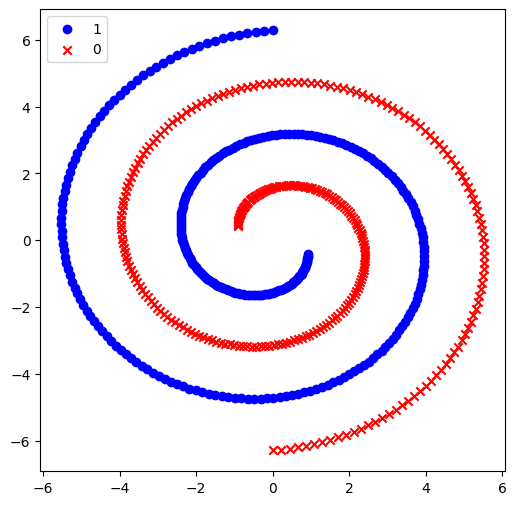

In [9]:
X, y = h.spiraldata(N=300)
h.visualize_2D(X.numpy(), y.numpy())

Now, we will create a multi-layer perceptron. In PyTorch, to create a model, we need to create a model class that overloads `nn.Module` and implement the `forward()` function that performs forward propagation.

Running the next cell creates a model class named `MLP` that overloads `nn.Module`. Note that `MLP` is a simple multi-layer perceptron with three hidden layers and ReLU transition functions.

In [10]:
class MLP(nn.Module):
    def __init__(self):
        # Call the constructor of the inherited module;
        # this line is always necessary.
        super().__init__()

        # All the layers with trainable parameters have to be
        # defined in the constructor.
        # Create a linear layer that takes input of dimension 2
        # and outputs a vector of dimension 64.
        # Similarly, create the consequent layers.
        self.fc1 = nn.Linear(in_features=2, out_features=64)
        self.fc2 = nn.Linear(in_features=64, out_features=32)
        self.fc3 = nn.Linear(in_features=32, out_features=16)

        # The last layer should output a two dimensional vector
        # where the first dimension corresponds to the network's
        # belief that the input belongs to class 0.
        # Similarly, second dimension corresponds to class 1.
        self.fc4 = nn.Linear(in_features=16, out_features=2)

    def forward(self, x):
        # Apply the first linear transformation to input x
        # then apply the ReLU transition to get the output
        # of the first hidden layer o1.
        # Similar procedures are done to get o2, o3.
        o1 = F.relu(self.fc1(x))
        o2 = F.relu(self.fc2(o1))
        o3 = F.relu(self.fc3(o2))

        # We do not apply any transition function to the output
        # of the final hidden layer.
        o4 = self.fc4(o3)
        return o4

Now, we can instantiate a model and do forward propagation by running the following cell:

In [11]:
# Instantiate a model
model_v1 = MLP()

# Run forward propagation
logits_v1 = model_v1(X)

# Print the output of the model; it should be (600, 2)
print(logits_v1.shape)

torch.Size([600, 2])


### 2. Define a Loss Function

To train a neural network, we need a loss function. Since we are doing a classification problem, we are going to use the cross entropy loss. Luckily, Pytorch has implemented this for us. For a comprehensive list of PyTorch implemented loss functions, please check out the [PyTorch 2.3 documentation for Loss Functions](https://pytorch.org/docs/2.3/nn.html#loss-functions).

The next cell creates the the cross-entropy loss function `loss_fn`. This loss function takes in logits and labels and return the loss value. More concretely, calling `loss_fn(logits, y)` will return the cross-entropy loss between the prediction `logits` and ground truth `y`.

In [12]:
loss_fn = nn.CrossEntropyLoss()

### 3. Define an Optimizer

We are going to use an SGD optimizer to optimize our MLP. Conveniently, PyTorch has implemented SGD for us.

The next cell defines an `optimizer_v1` by calling `torch.optim.SGD()` with the model parameters `model_v1.parameters()` and a learning rate `lr=0.1`.

In [13]:
optimizer_v1 = torch.optim.SGD(model_v1.parameters(), lr=0.1)

### 4. Training the Network

With all the ingredients we have, we are ready to train our multi-layer perceptrons.

In the next cell, `num_epochs_v1` is the number of times we are going to go through the dataset. This is a simple dataset so we are just going to do a vanilla Gradient Descent (GD) rather than minibatch Stochastic Gradient Descent (SGD).

In [14]:
num_epochs_v1 = 1200

losses_v1 = []
for epoch in range(num_epochs_v1):
    # Set the model to training mode;
    # this step is always necessary during training.
    model_v1.train()

    # PyTorch keeps track of all the gradients generated
    # throughout the whole training procedure.
    # But we only need the gradient of the current time step,
    # so we need to zero-out the gradient buffer.
    optimizer_v1.zero_grad()

    # Do forward propagation
    logits_v1 = model_v1(X)

    # Calculate the loss
    loss_v1 = loss_fn(logits_v1, y)

    # Do backward propagation
    loss_v1.backward()

    # Update the model parameters
    optimizer_v1.step()

    # Get the prediction
    prediction_v1 = torch.argmax(logits_v1, dim=1)

    # PyTorch supports elements element-wise comparison
    acc_v1 = torch.mean((prediction_v1 == y).float())

    losses_v1.append(loss_v1.item())

    # Print the loss value every 100 epochs
    if (epoch + 1) % 100 == 0:
        print(f"Epoch: {epoch + 1}/{num_epochs_v1}")
        print(f"Accuracy: {acc_v1:.4f}")
        print(f"Loss: {losses_v1[-1]:.4f}")
        print()

Epoch: 100/1200
Accuracy: 0.6200
Loss: 0.6562

Epoch: 200/1200
Accuracy: 0.6633
Loss: 0.6490

Epoch: 300/1200
Accuracy: 0.6833
Loss: 0.6380

Epoch: 400/1200
Accuracy: 0.6483
Loss: 0.6236

Epoch: 500/1200
Accuracy: 0.6267
Loss: 0.6031

Epoch: 600/1200
Accuracy: 0.6300
Loss: 0.5791

Epoch: 700/1200
Accuracy: 0.6900
Loss: 0.5237

Epoch: 800/1200
Accuracy: 0.8450
Loss: 0.4396

Epoch: 900/1200
Accuracy: 0.9067
Loss: 0.2649

Epoch: 1000/1200
Accuracy: 0.9983
Loss: 0.0843

Epoch: 1100/1200
Accuracy: 1.0000
Loss: 0.0362

Epoch: 1200/1200
Accuracy: 1.0000
Loss: 0.0168



Next, plot the training loss per epoch:

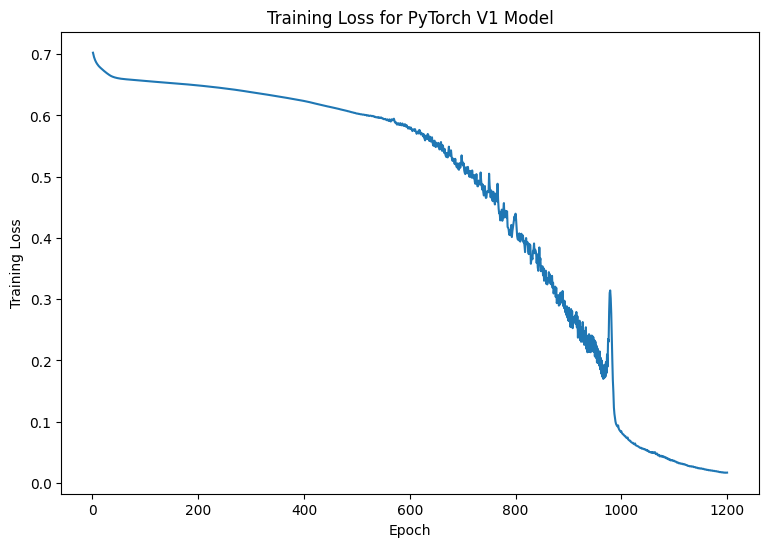

In [15]:
plt.figure(figsize=(9, 6))
plt.plot(range(1, num_epochs_v1 + 1), losses_v1, label="Training Loss")
plt.ylabel("Training Loss")
plt.xlabel("Epoch")
plt.title("Training Loss for PyTorch V1 Model")
plt.show()

### 5. Evaluate the Network

To evaluate the network, we call the `eval()` method on `model_v1`, do a forward pass and tell PyTorch to not keep track of the gradient calculation to save memory, make predictions, and finally calculate the accuracy.

In [16]:
# Initiate evaluation
model_v1.eval()

# Forward pass
with torch.no_grad():
    logits_v1 = model_v1(X)

# Make predictions
prediction_v1 = torch.argmax(logits_v1, dim=1)

# Calculate accuracy
print(f"Accuracy: {torch.mean((prediction_v1 == y).float()).item() * 100:.2f}%")

Accuracy: 100.00%


Running the next cell creates a visualization of the model.

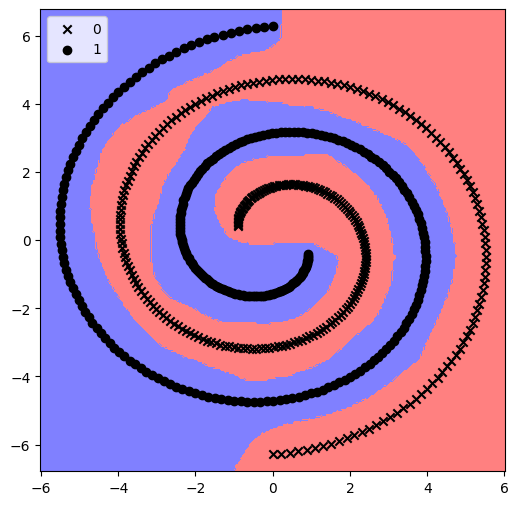

In [17]:
h.visclassifier_pt(model_v1, X.numpy(), y.numpy())

### (Optional) Exercise

In the following cell, you will create another multi-layer perceptron with 2 hidden layers. The first hidden layer has 256 neurons and the second hidden layer has 128 neurons. We have provided the following code stub. What you need to is define `self.fc1`, `self.fc2`, and `self.fc3` using `nn.Linear()` with the correct values for `in_features` and `out_features`.

In [25]:
class MLP_v2(nn.Module):
    def __init__(self):
        # Call the constructor of the inherited module;
        # this line is always necessary.
        super().__init__()

        # Define self.fc1, self.fc2, self.fc3, makes sure that the output of one layer equals the input of the next
        self.fc1 = nn.Linear(2, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 2)
        # END OF YOUR CODE

    def forward(self, x):
        o1 = F.relu(self.fc1(x))
        o2 = F.relu(self.fc2(o1))
        o3 = self.fc3(o2)
        return o3

If you create the right model, you should be able to pass the tests in the next cell.

In [26]:
model_v2 = MLP_v2()

# Checking the size of the parameters in the first layer
fc1_parameters = list(model_v2.fc1.parameters())

# The weight should have shape (256, 2)
assert fc1_parameters[0].shape == (256, 2)

# The bias should have shape (256,)
assert fc1_parameters[1].shape == (256,)

# Checking the size of the parameters in the second layer
fc2_parameters = list(model_v2.fc2.parameters())
assert fc2_parameters[0].shape == (128, 256)
assert fc2_parameters[1].shape == (128,)

# Checking the size of the parameters in the last layer
fc3_parameters = list(model_v2.fc3.parameters())
assert fc3_parameters[0].shape == (2, 128)
assert fc3_parameters[1].shape == (2,)

The next cell creates a new optimizer. Feel free to play around with the learning rate `lr=0.1` for `my_optimizer_v2`.

In [27]:
optimizer_v2 = torch.optim.SGD(model_v2.parameters(), lr=0.1)

Now we train the model with only 1,000 passes through the dataset, as opposed to 1,200 for the V1 model.

In [28]:
num_epochs_v2 = 1000

losses_v2 = []
for epoch in range(num_epochs_v2):
    # Set the model to training mode;
    # this step is always necessary during training.
    model_v2.train()

    # PyTorch keeps track of all the gradients generated
    # throughout the whole training procedure.
    # But we only need the gradient of the current time step,
    # so we need to zero-out the gradient buffer.
    optimizer_v2.zero_grad()

    # Do forward propagation
    logits_v2 = model_v2(X)

    # Calculate the loss
    loss_v2 = loss_fn(logits_v2, y)

    # Do backward propagation
    loss_v2.backward()

    # Update the model parameters
    optimizer_v2.step()

    # Get the prediction
    prediction_v2 = torch.argmax(logits_v2, dim=1)

    # PyTorch supports elements element-wise comparison
    acc_v2 = torch.mean((prediction_v2 == y).float())

    losses_v2.append(loss_v2.item())

    # Print the loss value every 100 epochs
    if (epoch + 1) % 100 == 0:
        print(f"Epoch: {epoch + 1}/{num_epochs_v2}")
        print(f"Accuracy: {acc_v2:.4f}")
        print(f"Loss: {losses_v2[-1]:.4f}")
        print()

Epoch: 100/1000
Accuracy: 0.6300
Loss: 0.6295

Epoch: 200/1000
Accuracy: 0.6267
Loss: 0.5995

Epoch: 300/1000
Accuracy: 0.6333
Loss: 0.5469

Epoch: 400/1000
Accuracy: 0.8083
Loss: 0.4643

Epoch: 500/1000
Accuracy: 0.8217
Loss: 0.3855

Epoch: 600/1000
Accuracy: 0.8350
Loss: 0.3354

Epoch: 700/1000
Accuracy: 0.9300
Loss: 0.2020

Epoch: 800/1000
Accuracy: 0.9550
Loss: 0.0854

Epoch: 900/1000
Accuracy: 0.9950
Loss: 0.0681

Epoch: 1000/1000
Accuracy: 1.0000
Loss: 0.0248



Plot the training loss per epoch:

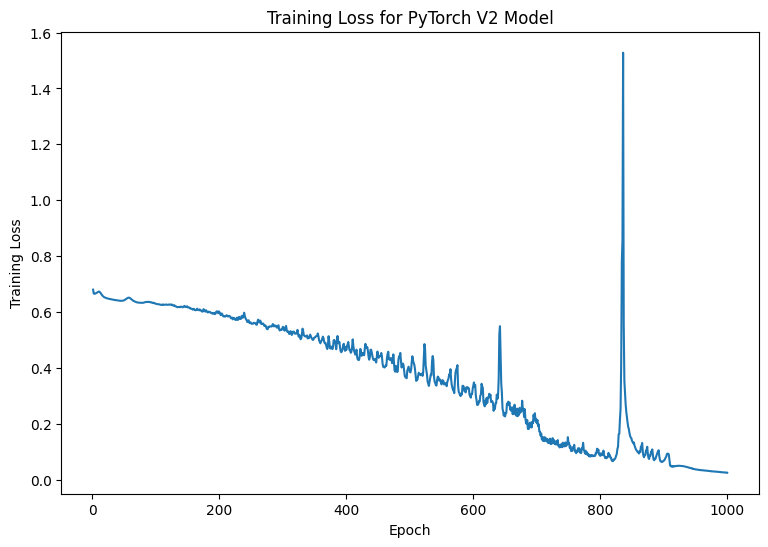

In [29]:
plt.figure(figsize=(9, 6))
plt.plot(range(1, num_epochs_v2 + 1), losses_v2, label="Training Loss")
plt.ylabel("Training Loss")
plt.xlabel("Epoch")
plt.title("Training Loss for PyTorch V2 Model")
plt.show()

Again, to evaluate the network, we call the `eval()` method on `model_v2`, do a forward pass and tell PyTorch to not keep track of the gradient calculation to save memory, make predictions, and finally calculate the accuracy.

In [30]:
# Initiate evaluation
model_v2.eval()

# Forward pass
with torch.no_grad():
    logits_v2 = model_v2(X)

# Make predictions
prediction_v2 = torch.argmax(logits_v2, dim=1)

# Calculate accuracy
print(f"Accuracy: {torch.mean((prediction_v2 == y).float()).item() * 100:.2f}%")

Accuracy: 100.00%


Now visualize the model:

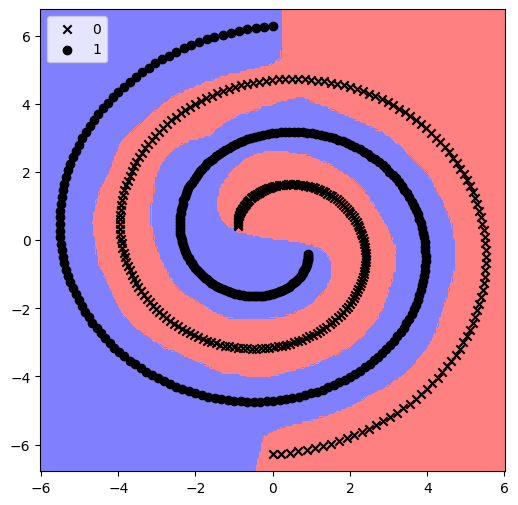

In [31]:
h.visclassifier_pt(model_v2, X.numpy(), y.numpy())

## TensorFlow Approach

With TensorFlow, you can follow the simple 5 steps below to train your model on data.

Like in PyTorch, first you define your network with layers. However, unlike in PyTorch, the model definition in TensorFlow also defines the exact forward propagation. In other words, TensorFlow automatically attaches the layers for you whereas PyTorch requires you to define a `forward` method for forward propagation. The latter approach has both an upside and a downside — it gives the user more flexibility but demands repetitive work.

With TensorFlow's `compile` and `fit` methods, you can easily and cleanly perform training. Again, PyTorch provides the user more flexibility by requiring them to write the training/evaluation step in a Python-ic way. On the other hand, TensorFlow provides built-in functions that conveniently connect to `compile` and `fit`. 

[TensorFlow's recent versions provide more control on the training step like PyTorch.](https://www.tensorflow.org/tutorials/quickstart/advanced)

### Training the V1 Model in TensorFlow

1. Creating a model

2. Define a loss function

3. Define an optimizer

4. Training the network

5. Evaluate the network

**Notes:**

- Steps 1-4 are carried out by the next two code cells and the code for step 5 is in the cell after that.  

- We use the `SparseCategoricalCrossentropy` loss function since the true `y` is a vector of are binary labels of shape `len(data)` and the logit outputs of the model is a matrix of logits of shape `len(data), 2`. Since the outputs are not normalized between 0 and 1, we specify `from_logits=True`.

- By default, TensorFlow outputs loss and metrics at the end of every epoch. We use a custom logger function to only output every 25 epochs.

In [32]:
X_np = X.numpy()
y_np = y.numpy()

# Create model
model_tf = tf.keras.Sequential(
    [
        tf.keras.Input(shape=(2,)),
        tf.keras.layers.Dense(64, activation="relu", name="fc1"),
        tf.keras.layers.Dense(32, activation="relu", name="fc2"),
        tf.keras.layers.Dense(16, activation="relu", name="fc3"),
        tf.keras.layers.Dense(2, activation=None, name="fc4"),
    ]
)

# Display model parameters
model_tf.summary()

# Define loss function
loss_fn_tf = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)

# Define optimizer
optimizer_tf = tf.keras.optimizers.SGD(learning_rate=0.1)

# Train network
model_tf.compile(optimizer=optimizer_tf, loss=loss_fn_tf, metrics=["accuracy"])
num_epochs_tf = 100
history = model_tf.fit(
    X_np,
    y_np,
    epochs=num_epochs_tf,
    verbose=0,  # Disable the default progress bar
    callbacks=[h.ProgBarLoggerNEpochs(num_epochs_tf, every_n=25)],
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ fc1 (Dense)                     │ (None, 64)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc3 (Dense)                     │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc4 (Dense)                     │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,834 (11.07 KB)

 Trainable params: 2,834 (11.07 KB)

 Non-trainable params: 0 (0.00 B)

Epoch: 25/100
Accuracy: 0.6367
Loss: 0.6331

Epoch: 50/100
Accuracy: 0.6750
Loss: 0.5438

Epoch: 75/100
Accuracy: 0.9300
Loss: 0.2193

Epoch: 100/100
Accuracy: 1.0000
Loss: 0.0087



The method `model.summary()` is an incredibly useful tool. It also shows the number of parameters per layer. 

For example, since the first layer is $64$ units and the input dimension is $2$, the first weight matrix $\mathbf{W}_1$ must be of shape $2 \times 64$. Recall that $\mathbf{Z}_1 = \sigma(\mathbf{W}_1 \mathbf{x} + \mathbf{b})$ where $\mathbf{x}$ is one input point and $\mathbf{b}$ is the bias vector added after matrix multiplication of $\mathbf{W}_1$ with $\mathbf{x}$. To match dimensions, the vectors $\mathbf{b}$ and $\mathbf{W}_1 \mathbf{x}$ must be of equal length, i.e., $64$. Hence, how many parameters does the first layer have in total?

Well, it is $2 \times 64 + 64 = 192$, which we see in the summary table. Likewise, the second layer has $64 \times 32 + 32 = 2080$ parameters, and so on.

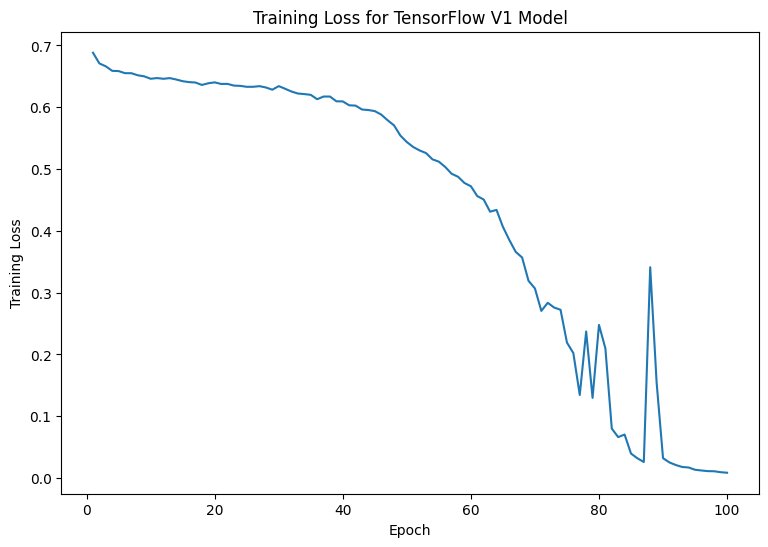

In [33]:
losses_tf = history.history["loss"]

plt.figure(figsize=(9, 6))
plt.plot(range(1, num_epochs_tf + 1), losses_tf, label="Training Loss")
plt.ylabel("Training Loss")
plt.xlabel("Epoch")
plt.title("Training Loss for TensorFlow V1 Model")
plt.show()

Now we evaluate the network:

In [34]:
# Evaluate model
model_tf.evaluate(X_np, y_np)

# Get logits to calculate accuracy manually
print("Calculating accuracy in TensorFlow manually with logits...")
logits_tf = model_tf(X_np)

# Make predictions
prediction_tf = tf.argmax(logits_tf, axis=1)

# Calculate accuracy
acc_tf = tf.reduce_mean(tf.cast(prediction_tf == y, tf.float32)).numpy()
print(f"Accuracy: {acc_tf * 100:.2f}%")

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 0.0065  
Calculating accuracy in TensorFlow manually with logits...
Accuracy: 100.00%


Finally, you can visualize the model:

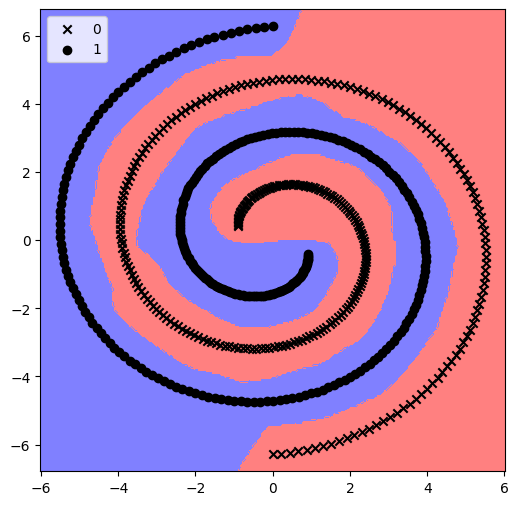

In [35]:
h.visclassifier_tf(model_tf, X_np, y_np)